In [3]:
import numpy as np 
import random
import matplotlib.pyplot as plt

In [4]:
# Function ex 1 #

def sample_discrete(x, p):
    s = [0]
    n = len(p)
    for i in range(n):
        s.append(s[-1] + p[i])
    u = random.random()
    for i in range(1, n + 1):
        if s[i-1] <= u < s[i]:
            return x[i-1]
    return x[-1]

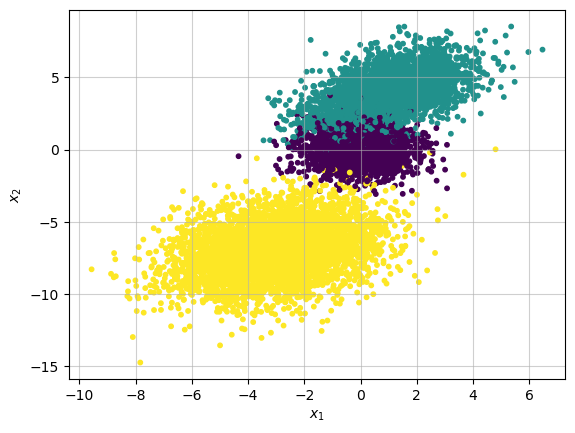

In [5]:
alpha = [0.2, 0.3, 0.5]
mu = [[0,0], [1,4], [-3,-7]]
Sigma = [[[1, 0], [0, 1]], [[2, 1], [1,2]], [[3,1], [1, 3]]]

m = len(alpha)
n = 10000

Z = np.zeros(n, dtype=int)
X = np.zeros((n, 2))

for i in range(n):
    Z[i] = sample_discrete(list(range(m)), alpha)
    X[i] = np.random.multivariate_normal(mu[Z[i]], Sigma[Z[i]])

plt.scatter(X[:, 0], X[:, 1], c=Z, s=10, cmap="viridis")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.grid(alpha=0.6)
plt.show()

In [6]:
def gaussian_pdf(x, mu, Sigma):
    d = len(mu)
    det = np.linalg.det(Sigma)
    inv = np.linalg.inv(Sigma)

    exp = -0.5*(x-mu).T @ inv @ (x-mu)
    den = np.sqrt((2 * np.pi)**d*det)

    return np.exp(exp)/den

In [12]:
def EM_algo(X, K, N_it):
    n, d = X.shape
    alpha = np.ones(K)/K
    indices = np.random.choice(n, K, replace=False)
    mu = X[indices].copy()
    Sigma = np.array([np.eye(d)] * K)
    loglikelihood = []

    reg=1e-6

    gamma = np.zeros((n,K))

    for _ in range(N_it):
        # E-step 
        logl = 0
        for i in range(n):
            norm=0
            for k in range(K):
                gamma[i, k] = alpha[k]*gaussian_pdf(X[i], mu[k], Sigma[k])
                norm += gamma[i, k]

            for k in range(K):
                gamma[i, k] /= norm

            logl += np.log(norm)

        loglikelihood.append(logl)

        # M-step
        for k in range(K):
            N_k = 0
            for i in range(n):
                N_k += gamma[i, k]

            # alpha update
            alpha[k] = N_k/n

            # mu update
            mu_update = np.zeros(d)
            for i in range(n):
                mu_update += gamma[i, k]*X[i]
            mu[k] = mu_update/(N_k+reg)

            # Sigma update
            Sigma_update = np.zeros((d, d))
            for i in range(n):
                diff = (X[i] - mu[k]).reshape(d, 1)
                Sigma_update += gamma[i, k]*(diff @ diff.T)
            Sigma[k] = Sigma_update/(N_k+reg)

    return alpha, mu, Sigma, gamma, loglikelihood

In [13]:
alpha_hat, mu_hat, Sigma_hat, gamma, loglikelihood = EM_algo(X, K=3, N_it=100)